In [59]:
from scipy import linalg as la
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.decomposition import TruncatedSVD
from sklearn.datasets import load_digits
np.set_printoptions(precision=2,suppress=True)

#####
<font color="#2c3e50" size="6"><div style="
    font-family: sans-serif;
    font-size: 1.2em;
    font-weight: 700;
    line-height: 1.2;
    background-color: #d9e6f2;
    border-radius: 8px;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    padding: 0.5em 1em;
    margin-top: 1em;
    margin-bottom: 0.6em;
    box-shadow: 0 2px 6px rgba(0,0,0,0.1);
" align="center">
5.4 Singular Value Decomposition
</div></font>

In Chapter 5.1, we showed that every symmetric matrix $A$ can be factored as $A=PDP^T$, where $P$ is an orthogonal matrix and $D$ is a diagonal matrix with the eigenvalues of $A$ along its main diagonal. If $A$ is not symmetric, we might be able to factor it as $A=PDP^{-1}$, where $P$ is just an invertible matrix. However, as we learned in Chapter 3.2, not every matrix is diagonalizable. In this chapter, we will show that every matrix $A$ has a factorization of the form $A=U\Sigma V^T$, where $U$ and $V$ are orthogonal matrices and $\Sigma$ is a matrix that is almost diagonal. We use the term “diagonal” loosely here because we will need to slightly modify the definition of a diagonal matrix. This is a very important type of factorization. At the end of this chapter, we will see how it can be used for image compression and dimensionality reduction.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Singular Values</b>
</div></font> 

Recall that for any matrix $A$, the matrix $A^TA$ is symmetric and positive semidefinite. Therefore, $A^TA$ is orthogonally diagonalizable and has nonnegative eigenvalues. To see why its eigenvalues are nonnegative, let $\lambda$ be an eigenvalue of $A^TA$ with a corresponding unit eigenvector $\bf v$. Then

$$||A{\bf v}||^2=(A{\bf v})^T (A{\bf v})= {\bf v}^TA^TA{\bf v}={\bf v}^T \lambda {\bf v}=\lambda {\bf v}^T{\bf v}=\lambda ||{\bf v}||^2=\lambda$$

Since $||A{\bf v}||^2\geq 0$, we must have $\lambda\geq 0$.

Since all eigenvalues of $A^TA$ are nonnegative, we can take their square roots.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Definition</strong><br> If $A$ is an $m\times n$ matrix, then the <strong>singular values</strong> of $A$ are the square roots of the eigenvalues of $A^TA$. They are denoted by $\sigma_1, \cdots, \sigma_n$. We usually arrange them in descending order, so that $\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_n$.
</div>



To see why singular values are useful, let's examine how they arise from a geometric point of view.

---
**<font color="red">Example 1</font>**

Consider the linear transformation ${\bf x} \rightarrow A{\bf x}$, where $A=\begin{bmatrix} 22 & -2 & -13 \\ -4 & 14 & 16 \end{bmatrix}$. It maps the unit sphere in $\mathbb{R}^3$ onto a filled-in ellipse in $\mathbb{R}^2$.

**a.** Find a unit vector ${\bf x}$ that maximizes $||A{\bf x}||$ and compute the maximum value.

**b.** Let ${\bf v}_1$ be the vector that maximizes $||A{\bf x}||$ in part a. Find a unit vector ${\bf x}$ that maximizes $||A{\bf x}||$ subject to the constraint ${\bf x}^T{\bf v}_1=0$, and compute the maximum value.

<center> <img src="data:image/png;base64,  ...
 " width="80%"> </center>

**Solution.**


We will solve both parts at the same time.

Note that the vector $\bf x$ that maximizes $||A{\bf x}||$ also maximizes $||A{\bf x}||^2$. Since $||A{\bf x}||^2 = (A{\bf x})^T(A{\bf x})={\bf x}^T (A^TA){\bf x}$, the problem is equivalent to maximizing the quadratic form ${\bf x}^T (A^TA){\bf x}$ subject to the appropriate constraints. 

For part (**a.**), the constraint is $||{\bf x}||=1$. For part (**b.**), the constraints are $||{\bf x}||=1$ and ${\bf x}^T{\bf v}_1=0$. Therefore, the maximum values in part (**a.**) and (**b.**) are given by the largest and second-largest eigenvalues of $A^TA$, respectively. 

First, we need to find the eigenvalues of $A^TA$ and the corresponding unit eigenvectors. We compute:

$$A^TA=\begin{bmatrix} 22 & -4 \\ -2 & 14 \\ -13 & 16 \end{bmatrix}\begin{bmatrix} 22 & -2 & -13 \\ -4 & 14 & 16 \end{bmatrix} = \begin{bmatrix} 500 & -100 & -350 \\ -100 & 200 & 250 \\ -350 & 250 & 425 \end{bmatrix}$$

The eigenvalues of $A^TA$ are $$\lambda_1= 900, \quad\lambda_2=225, \text{ and } \quad \lambda_3=0$$ and the corresponding unit eigenvectors are 
$${\bf v}_1 =\begin{bmatrix} -2/3 \\ 1/3 \\ 2/3 \end{bmatrix}, \quad {\bf v}_2 =\begin{bmatrix} 2/3 \\ 2/3 \\ 1/3 \end{bmatrix}, \text{ and }\quad {\bf v}_3 =\begin{bmatrix} 1/3 \\ -2/3 \\ 2/3 \end{bmatrix}$$

For part (**a.**), the maximum value of $||A{\bf x}||^2$ is the largest eigenvalue $\lambda_1=900$ and it is achieved at the unit eigenvector ${\bf v}_1$. Therefore, the maximum value for $||A{\bf x}||$ is $\sqrt{\lambda_1}=\sqrt{900}=30$ and it is still achieved at ${\bf v}_1$. Geometrically, $A{\bf v}_1$ is a point on the boundary of the ellipse that is farthest from the origin:

$$A{\bf v}_1=\begin{bmatrix} 22 & -2 & -13 \\ -4 & 14 & 16 \end{bmatrix}\begin{bmatrix} -2/3 \\ 1/3 \\ 2/3 \end{bmatrix}=\begin{bmatrix} -24 \\ 18 \end{bmatrix}$$

Indeed, $$||A{\bf v}_1||=\sqrt{(-24)^2+18^2}=30$$

For part (**b.**), we need to maximize $||A{\bf x}||^2$ subject to the constraints $||{\bf x}||=1$ and ${\bf x}^T{\bf v}_1=0$. It is given by the second-largest eigenvalue $\lambda_2=225$ and this maximum is achieved at the unit eigenvector ${\bf v}_2$. Therefore, this maximum value of $||A{\bf x}||$ under these constraints is $\sqrt{\lambda_2}=\sqrt{225}=15$. Geometrically, $A{\bf v}_2$ is the closest point on the boundary of the ellipse to the origin:

$$A{\bf v}_2=\begin{bmatrix} 22 & -2 & -13 \\ -4 & 14 & 16 \end{bmatrix}\begin{bmatrix} 2/3 \\ 2/3 \\ 1/3 \end{bmatrix}=\begin{bmatrix} 9 \\ 12 \end{bmatrix}$$
Indeed, $$||A{\bf v}_2||=\sqrt{9^2+12^2}=15$$

So, the answers to this problem are given by the two largest singular values of $A$: $\sigma_1=\sqrt{\lambda_1}=30$ and $\sigma_2=\sqrt{\lambda_2}=15$

What about the third singular value $\sigma_3=\sqrt{\lambda_3}=0$?
This tells us that $A{\bf v}_3={\bf 0}$.
In other words, the entire direction of ${\bf v}_3$ is collapsed to the origin by the transformation. This is what allows a three-dimensional object to be mapped into a two-dimensional space.

---

From this example, we can see that singular values of $A$ play a similar role to eigenvalues of a symmetric matrix. Moreover, the images under $A$ of the eigenvectors of $A^TA$ corresponding to nonzero singular values form an orthogonal basis for the column space of $A$.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem</strong><br> Let $A$ be an $m \times n$ matrix and let $\{ {\bf v}_1, \cdots, {\bf v}_n \}$ be an orthonormal basis of $\mathbb{R}^n$ consisting of eigenvectors of $A^TA$ arranged in descending order of corresponding eigenvalues. If $A$ has $r$ nonzero singular values, then $\{ A{\bf v}_1, \cdots, A{\bf v}_r \}$ is an orthogonal basis for $Col(A)$. Consequently, $rank(A)=r$.
</div>



######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>SVD</b>
</div></font> 

Before introducing the main concept of this chapter, let's extend the definition of a diagonal matrix to non-square matrices. We define the **main diagonal** of an $m \times n$ matrix to be the line of entries starting at the upper-left corner and continuing diagonally as far as possible. These entries are called the **diagonal entries**. We say that an $m \times n$ matrix $A$ is a **rectangular diagonal matrix** if all non-diagonal entries are zero. 

The singular value decomposition uses rectangular diagonal matrices of the form

 $$\Sigma=\begin{align*}
\left[
\begin{array}{c|c}
D_r & O  \\ \hline O & O 
\end{array}
\right],
\end{align*}$$

where $D_r$ is an $r \times r$ diagonal matrix whose diagonal entries are nonzero and the remaining blocks are zero matrices of the appropriate sizes. If $r=m$ or $r=n$, some of the zero blocks are absent.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #55a868;
    background-color: rgba(10,150,50,0.16);
    margin: 0.4em 0;
">
<strong>🏛️ Theorem (SVD) </strong><br> Let $A$ be an $m \times n$ matrix of rank $r$, and let its nonzero singular values be $\sigma_1 \geq \sigma_2 \geq \cdots \geq \sigma_r>0$. Then $A$ can be factored as $$A=U\Sigma V^T,$$ where $U$ is an $m \times m$ orthogonal matrix, $V$ is an $n \times n$ orthogonal matrix, and $\Sigma$ is an $m\times n$ rectangular diagonal matrix whose first $r$ diagonal entries are $\sigma_1,\cdots,\sigma_r$.
</div>




This factorization is called **singular value decomposition (SVD)** of $A$. Matrices $U$ and $V$ are not uniquely determined by $A$, but $\Sigma$ must contain singular values in descending order. Columns of $U$ and $V$ are called **left singular vectors** of $A$ and **right singular vectors** of $A$, respectively.

Let's prove this theorem.

**Proof.**

Let $\{ {\bf v}_1, \cdots, {\bf v}_n \}$ be an orthonormal basis of $\mathbb{R}^n$ consisting of eigenvectors of $A^TA$ arranged in descending order of corresponding eigenvalues. The first $r$ eigenvalues are positive, and the remaining $n-r$ eigenvalues are zero. 

Let $${\bf u}_i=\frac{1}{||A{\bf v}_i||}A{\bf v}_i=\frac{1}{\sigma_i}A{\bf v}_i\quad \text{ for } i=1,\cdots, r$$


For $i \neq j$ $$(A{\bf v}_i)^T A{\bf v}_j = {\bf v_i}^TA^TA{\bf v}_j={\bf v_i}^T(\sigma_j^2{\bf v}_j)=0$$
Therefore, $\{ {\bf u}_1, \cdots, {\bf u}_r \}$ is an orthonormal set in $\mathbb{R}^m$. It is an orthonormal basis for $Col(A)$, but it may not be a basis for all of $\mathbb{R}^m$. We therefore extend it to an orthonormal basis $\{{\bf u}_1,\cdots,{\bf u}_r,{\bf u}_{r+1},\cdots,{\bf u}_m\}$ of $\mathbb{R}^m$.


Note: This part is tricky. We will see how to do it in the later examples. It involves solving a linear system and applying the Gram-Schmidt process. 

Now set $$U=\begin{bmatrix}  {\bf u}_1 & \cdots &  {\bf u}_m\end{bmatrix}\quad \text{ and }\quad V=\begin{bmatrix}  {\bf v}_1 & \cdots &  {\bf v}_n\end{bmatrix}$$

By construction, both $U$ and $V$ are orthogonal matrices.

Using the fact that $A{\bf v}_i = \sigma_i {\bf u}_i$, and for $i>r$, $A{\bf v}_i  = {\bf 0}$ we have



<div style="display: flex; justify-content: center;">
    <div style="text-align: left;">
        $AV =A\begin{bmatrix}  {\bf v}_1 & \cdots &  {\bf v}_n\end{bmatrix}$<br>
        $\quad \quad  = \begin{bmatrix} A{\bf v}_1 & \cdots &  A{\bf v}_n\end{bmatrix}$<br>
        $\quad \quad =\begin{bmatrix} A{\bf v}_1 & \cdots &  A{\bf v}_r & {\bf 0} & \cdots & {\bf 0} \end{bmatrix}$<br>
        $ \quad \quad =\begin{bmatrix} \sigma_1{\bf u}_1 & \cdots &  \sigma_r{\bf u}_r & {\bf 0} & \cdots & {\bf 0} \end{bmatrix}$<br>
    </div>
</div>

Let $\Sigma$ be the rectangular diagonal matrix with $\sigma_1,\cdots,\sigma_r$ on its main diagonal. Then



 $$U\Sigma=\begin{align*}
\left[
\begin{array}{}
{\bf u}_1 & \cdots &  {\bf u}_m
\end{array}
\right]
\left[
\begin{array}{ccc|c}
\sigma_1 &  &  O &  \\ & \ddots & & O \\ O & & \sigma_r & \\ \hline & O & & O
\end{array}
\right]=
\left[
\begin{array}{}
\sigma_1{\bf u}_1 & \cdots &  \sigma_r{\bf u}_r & {\bf 0} & \cdots & {\bf 0}
\end{array}
\right]=AV
\end{align*}$$

Since $V$ is an orthogonal matrix, $VV^T=I$. Therefore, $$U\Sigma V^T=AVV^T=A$$

---

Finding the SVD of matrices that have more rows than columns is a bit different than for the ones that have more columns than rows. The latter case is a bit more straightforward.

---
**<font color="red">Example 2</font>**

Find the SVD of the matrix $A=\begin{bmatrix} 1 & -2 & -1 \\ 1 & 1 & 1 \end{bmatrix}$

**Solution.**

We begin by orthogonally diagonalizing $A^TA$:
$$A^TA=\begin{bmatrix} 1 & 1 \\-2 & 1 \\ -1& 1\end{bmatrix}\begin{bmatrix} 1 & -2 & -1 \\ 1 & 1 & 1 \end{bmatrix}=\begin{bmatrix} 2 & -1 & 0 \\ -1 & 5 & 3 \\ 0 & 3 & 2 \end{bmatrix}$$

The eigenvalues of $A^TA$ are $$\lambda_1 = 7, \quad \lambda_2=2 \quad \text{ and }\quad\lambda_3=0,$$
with corresponding unit eigenvectors

$${\bf v}_1 = \begin{bmatrix} -1/\sqrt{35} \\ 5/\sqrt{35} \\ 3/\sqrt{35}\end{bmatrix}, \quad {\bf v}_2 = \begin{bmatrix} 3/\sqrt{10} \\ 0 \\ 1/\sqrt{10}\end{bmatrix} \text{ and }\quad {\bf v}_3 = \begin{bmatrix} -1/\sqrt{14} \\ -2/\sqrt{14} \\ 3/\sqrt{14}\end{bmatrix}$$

We construct the orthogonal matrix $V$:

$$V=\begin{bmatrix} {\bf v}_1 & {\bf v}_2 & {\bf v}_3\end{bmatrix}=\begin{bmatrix} -1/\sqrt{35} & 3/\sqrt{10} & -1/\sqrt{14}\\ 5/\sqrt{35} & 0 & -2/\sqrt{14}\\ 3/\sqrt{35}& 1/\sqrt{10} & 3/\sqrt{14} \end{bmatrix}$$

The singular values of $A$ are $$\sigma_1 = \sqrt{7}, \quad \sigma_2=\sqrt{2} \quad \text{ and }\quad \sigma_3=0$$

Since $\Sigma$ must have the same dimension as $A$, it is a $2 \times 3$ matrix. The zero singular value does not appear on its main diagonal because there are only two diagonal positions:

$$\Sigma=\begin{bmatrix} \sqrt{7} & 0 & 0 \\ 0 & \sqrt{2} & 0\end{bmatrix}$$

Finally, we construct $U$. For each nonzero singular value, the corresponding column of $U$ is obtained by normalizing $A{\bf v}_i$. Since $||A{\bf v}_i||=\sigma_i$, we get

$${\bf u}_1=\frac{1}{\sigma_1}A{\bf v}_1=\frac{1}{\sqrt{7}}\begin{bmatrix} 1 & -2 & -1 \\ 1 & 1 & 1 \end{bmatrix}\begin{bmatrix} -1/\sqrt{35} \\ 5/\sqrt{35} \\ 3/\sqrt{35}\end{bmatrix}=\begin{bmatrix} -2/\sqrt{5} \\ 1/\sqrt{5}\end{bmatrix}$$
$${\bf u}_2=\frac{1}{\sigma_2}A{\bf v}_2=\frac{1}{\sqrt{2}}\begin{bmatrix} 1 & -2 & -1 \\ 1 & 1 & 1 \end{bmatrix}\begin{bmatrix} 3/\sqrt{10} \\ 0 \\ 1/\sqrt{10}\end{bmatrix}=\begin{bmatrix} 1/\sqrt{5} \\ 2/\sqrt{5}\end{bmatrix}$$

Since $U$ must be a $2 \times 2$ orthogonal matrix, these two vectors give all of its columns:

$$U=\begin{bmatrix} -2/\sqrt{5} & 1/\sqrt{5} \\ 1/\sqrt{5} & 2/\sqrt{5}\end{bmatrix}$$

And so, the singular value decomposition of $A$ is

$$A=U\Sigma V^T=\begin{bmatrix} -2/\sqrt{5} & 1/\sqrt{5} \\ 1/\sqrt{5} & 2/\sqrt{5}\end{bmatrix}\begin{bmatrix} \sqrt{7} & 0 & 0 \\ 0 & \sqrt{2} & 0\end{bmatrix}\begin{bmatrix}  -1/\sqrt{35} & 5/\sqrt{35} & 3/\sqrt{35} \\ 3/\sqrt{10}& 0 & 1/\sqrt{10} \\ -1/\sqrt{14}& -2/\sqrt{14} &3/\sqrt{14}\end{bmatrix}$$

---

If $A$ has more rows than columns, finding the SVD can require one additional step. In the next example, we find the SVD of such a matrix directly and, along the way, show how to extend an orthonormal set to an orthonormal basis, as discussed in the proof of the SVD theorem.

---
**<font color="red">Example 3</font>**

Find the SVD of the matrix $A=\begin{bmatrix} 1 & 1 \\ 1 & 1 \\ -1 & -1\end{bmatrix}$

**Solution.**

We begin by orthogonally diagonalizing $A^TA$:
$$A^TA=\begin{bmatrix} 1 & 1 & -1 \\ 1 & 1 & -1 \end{bmatrix}\begin{bmatrix} 1 & 1 \\ 1 & 1 \\ -1 & -1\end{bmatrix}=\begin{bmatrix} 3 & 3 \\ 3 & 3 \end{bmatrix}$$

The eigenvalues of $A^TA$ are $$\lambda_1 = 6 \quad \text{ and }\quad\lambda_2=0,$$
with corresponding unit eigenvectors

$${\bf v}_1 = \begin{bmatrix} 1/\sqrt{2} \\ 1/\sqrt{2} \end{bmatrix}\quad \text{ and }\quad {\bf v}_2 = \begin{bmatrix} -1/\sqrt{2} \\ 1/\sqrt{2} \end{bmatrix}$$

Hence, $$V=\begin{bmatrix} 1/\sqrt{2}&-1/\sqrt{2} \\ 1/\sqrt{2}&1/\sqrt{2}\end{bmatrix}$$

Matrix $\Sigma$ must be $3 \times 2$. Therefore, 
$$\Sigma = \begin{bmatrix} \sqrt{6} & 0 \\ 0 & 0 \\ 0 & 0\end{bmatrix}$$

Next, we construct the columns of $U$. We start the same way as in Example 2:

$${\bf u}_1=\frac{1}{\sigma_1}A{\bf v}_1=\frac{1}{\sqrt{6}}\begin{bmatrix} 1 & 1 \\ 1 & 1 \\ -1 & -1\end{bmatrix}\begin{bmatrix} 1/\sqrt{2} \\ 1/\sqrt{2} \end{bmatrix}=\begin{bmatrix} 1/\sqrt{3} \\ 1/\sqrt{3} \\ -1/\sqrt{3} \end{bmatrix}$$

This is as far as we can go. We cannot obtain ${\bf u}_2$ from $\frac{1}{\sigma_2}A{\bf v}_2$ because $\sigma_2=0$. However, $U$ must be a $3 \times 3$ matrix, so we need to extend the orthonormal set $\{ {\bf u}_1 \}$ to an orthonormal basis of $\mathbb{R}^3$. 

The remaining two vectors must be orthogonal to ${\bf u}_1$. Therefore, they must satisfy the equation ${\bf u}_1 ^T {\bf x} =0$. The solution space of this homogeneous equation has the following basis $$\left\{ \begin{bmatrix} -1 \\ 1 \\0 \end{bmatrix}, \begin{bmatrix} 1 \\ 0 \\1 \end{bmatrix} \right\}$$

These two vectors are both orthogonal to ${\bf u}_1$, but they are not orthogonal to each other. We therefore apply the Gram-Schmidt process and normalize the resulting vectors. This gives

$${\bf u}_2=\begin{bmatrix} -1/\sqrt{2} \\ 1/\sqrt{2} \\0 \end{bmatrix} \quad \text{ and } \quad{\bf u}_3=\begin{bmatrix} 1/\sqrt{6} \\ 1/\sqrt{6} \\2/\sqrt{6} \end{bmatrix}$$

Hence, 

$$U=\begin{bmatrix} 1/\sqrt{3} & -1/\sqrt{2}& 1/\sqrt{6}\\ 1/\sqrt{3} &  1/\sqrt{2} & 1/\sqrt{6}\\ -1/\sqrt{3}& 0 & 2/\sqrt{6} \end{bmatrix}$$

---

There is a small trick we can use when dealing with very wide matrices. Notice that if $A^T=U\Sigma V^T$, then $A=(A^T)^T=(U\Sigma V^T)^T=V\Sigma^TU^T$. This tells us that if we know the SVD of $A^T$, we automatically know the SVD of $A$ as well. If $A$ is an $m \times n$ matrix with $m<n$ then $A^TA$ is a large $n \times n$ matrix, while $AA^T$ is a smaller $m \times m$ matrix. Therefore, finding the eigenvalues of $AA^T$ is easier. On the other hand, it will require extending an orthonormal set to an orthonormal basis and possibly applying the Gram-Schmidt process. 


---
**<font color="red">Example 4</font>**

Find the SVD of the matrix $A=\begin{bmatrix} 0 & 2 & -2 \\ 1 & 0 & 0\end{bmatrix}$ by considering $A^T$.

**Solution**

Let $$B=A^T=\begin{bmatrix} 0 & 1 \\ 2 & 0 \\ -2 & 0\end{bmatrix}$$ Then we compute $B^TB$:

$$B^TB=\begin{bmatrix} 0 & 2 & -2 \\ 1 & 0 & 0 \end{bmatrix}\begin{bmatrix} 0 & 1 \\ 2 & 0 \\ -2 & 0\end{bmatrix}=\begin{bmatrix} 8 & 0 \\0& 1\end{bmatrix}$$

The eigenvalues are easy to see: $$\lambda_1 = 8 \quad \text{ and }\quad\lambda_2=1,$$
with corresponding unit eigenvectors

$${\bf v}_1 = \begin{bmatrix} 1 \\ 0\end{bmatrix} \quad \text{ and } \quad {\bf v}_2=\begin{bmatrix} 0 \\1  \end{bmatrix} $$

So, $$V=\begin{bmatrix}1 & 0\\   0 & 1 \end{bmatrix}$$

Matrix $\Sigma$ must be $3 \times 2$:

$$\Sigma=\begin{bmatrix} \sqrt{8} & 0\\ 0 & 1 \\ 0 & 0 \end{bmatrix}$$

Finally, we construct $U$.

$${\bf u}_1=\frac{1}{\sigma_1}B{\bf v}_1=\frac{1}{\sqrt{8}}\begin{bmatrix}  0 & 1 \\ 2 & 0 \\ -2 & 0 \end{bmatrix}\begin{bmatrix}1 \\0\end{bmatrix}=\begin{bmatrix} 0 \\ 1/\sqrt{2} \\ -1/\sqrt{2}\end{bmatrix}$$
$${\bf u}_2=\frac{1}{\sigma_2}B{\bf v}_2=\frac{1}{1}\begin{bmatrix}  0 & 1 \\ 2 & 0 \\ -2 & 0 \end{bmatrix}\begin{bmatrix} 0 \\1 \end{bmatrix}=\begin{bmatrix} 1 \\ 0 \\ 0\end{bmatrix}$$

Since $U$ must have three columns, we need to find a vector orthogonal to both ${\bf u}_1$ and ${\bf u}_2$. This vector must satisfy the following system of equations:



$$\left\{\begin{array}{l}
  {\bf u}_1^T{\bf x}=0 \\
  {\bf u}_2^T{\bf x}=0
\end{array}\right. \Rightarrow
\left\{\begin{array}{l}
  0x_1 +\frac{1}{\sqrt{2}}x_2 -\frac{1}{\sqrt{2}}x_3 = 0 \\
  1x_1 +0x_2 +0x_3 = 0
\end{array}\right. \Rightarrow
\left[
\begin{array}{ccc|c}
0 & \frac{1}{\sqrt{2}}  & -\frac{1}{\sqrt{2}} & 0\\ 1 & 0  & 0 & 0
\end{array}
\right]
$$


The solution space of this homogeneous system has the following basis $$\left\{ \begin{bmatrix} 0 \\ 1 \\1 \end{bmatrix} \right\}$$ Normalizing this basis vector produces ${\bf u}_3$:
$${\bf u}_3 = \begin{bmatrix} 0 \\ 1/\sqrt{2} \\1/\sqrt{2} \end{bmatrix}$$

And so,

$$U=\begin{bmatrix}0 & 1& 0\\ 1/\sqrt{2} &  0 & 1/\sqrt{2}\\ -1/\sqrt{2}& 0 & 1/\sqrt{2} \end{bmatrix}$$

We have $B=U\Sigma V^T.$ Taking the transpose gives the SVD of $A$:


$$A=B^T=(U \Sigma V^T )^T = V \Sigma^T U^T = \begin{bmatrix} 1 & 0 \\ 0 & 1\end{bmatrix} \begin{bmatrix} \sqrt{8} & 0  & 0\\ 0 & 1  & 0 \end{bmatrix}\begin{bmatrix}0 &  1/\sqrt{2} &  -1/\sqrt{2} \\ 1 & 0 & 0 \\ 0 &  1/\sqrt{2} & 1/\sqrt{2} \end{bmatrix}$$





---

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #aca210;
    background-color: rgba(190,190,20,0.16);
    margin: 0.4em 0;
">
<strong>🛠️ <font color="magenta">Practice: </font> </strong>  Try to find the SVD of the above matrix directly. You should see that although you no longer need to extend an orthonormal set to an orthonormal basis, finding the eigenvalues is more difficult.
</div>

---

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Outer Product Form of the SVD</b>
</div></font>  

If we consider SVD as a generalization of orthogonal diagonalization, then the **outer product form of the SVD** can be viewed as a generalization of spectral decomposition. Suppose $A$ is an $m \times n$ matrix with $rank(A)=r$. Let $\{ \sigma_1, \cdots, \sigma_r \}$ be nonzero singular values of $A$ arranged in descending order. Then




 $$A=U\Sigma V^T =\begin{align*}
\left[
\begin{array}{ccc|ccc}
{\bf u}_1 & \cdots & {\bf u}_r & {\bf u}_{r+1} & \cdots & {\bf u}_m
\end{array}
\right]\left[
\begin{array}{ccc|c}
\sigma_1 &  &  O &  \\ & \ddots & & O \\ O & & \sigma_r & \\ \hline & O & & O
\end{array}
\right]\left[
\begin{array}{}
{\bf v}_1^T \\ \vdots \\ {\bf v}_r^T \\ \hline {\bf v}_{r+1}^T \\ \vdots \\ {\bf v}_n^T
\end{array}
\right]
\end{align*} $$
$$ =\begin{align*}
\left[
\begin{array}{ccc}
{\bf u}_1 & \cdots & {\bf u}_r 
\end{array}
\right]\left[
\begin{array}{}
\sigma_1 &  &  O  \\ & \ddots &  \\ O & & \sigma_r
\end{array}
\right]\left[
\begin{array}{}
{\bf v}_1^T \\ \vdots \\ {\bf v}_r^T 
\end{array}
\right]=\sigma_1{\bf u}_1{\bf v}_1^T+\cdots+\sigma_r{\bf u}_r{\bf v}_r^T
\end{align*} $$

Each matrix ${\bf u}_i{\bf v}_i^T$ is an outer product. Therefore, we can write

$$\require{bbox}\bbox[10px, border: 2px solid blue]{A=\sum_{i=1}^r \sigma_i{\bf u}_i{\bf v}_i^T}$$  


---
**<font color="red">Example 5</font>**

Find the outer product form of the SVD for $A=\begin{bmatrix} 1 & -2 & -1 \\ 1 & 1 & 1 \end{bmatrix}$ from Example 2.

**Solution.**

The matrix $A$ has two nonzero singular values: $\sigma_1=\sqrt{7}$ and $\sigma_2=\sqrt{2}$. The corresponding columns of $V$ and $U$ are

$${\bf v}_1 = \begin{bmatrix} -1/\sqrt{35} \\ 5/\sqrt{35} \\ 3/\sqrt{35}\end{bmatrix}, \quad {\bf v}_2 = \begin{bmatrix} 3/\sqrt{10} \\ 0 \\ 1/\sqrt{10}\end{bmatrix}, \quad {\bf u}_1=\begin{bmatrix} -2/\sqrt{5} \\ 1/\sqrt{5}\end{bmatrix} \quad \text{ and } \quad{\bf u}_2=\begin{bmatrix} 1/\sqrt{5} \\ 2/\sqrt{5}\end{bmatrix}$$

Then

$$\sigma_1{\bf u}_1{\bf v}_1^T=\sqrt{7}\begin{bmatrix} -2/\sqrt{5} \\ 1/\sqrt{5}\end{bmatrix}\begin{bmatrix} -1/\sqrt{35} & 5/\sqrt{35} & 3/\sqrt{35}\end{bmatrix} = \begin{bmatrix} 2/5 & -2 & -6/5 \\ -1/5 & 1 & 3/5 \end{bmatrix}$$
and 
$$\sigma_2{\bf u}_2{\bf v}_2^T=\sqrt{2}\begin{bmatrix} 1/\sqrt{5} \\ 2/\sqrt{5}\end{bmatrix}\begin{bmatrix} 3/\sqrt{10}& 0& 1/\sqrt{10}\end{bmatrix} = \begin{bmatrix} 3/5 & 0 & 1/5 \\ 6/5 & 0 & 2/5 \end{bmatrix}$$

Hence, 

$$A=\sigma_1{\bf u}_1{\bf v}_1^T+\sigma_2{\bf u}_2{\bf v}_2^T= \begin{bmatrix} 2/5 & -2 & -6/5 \\ -1/5 & 1 & 3/5 \end{bmatrix}+\begin{bmatrix} 3/5 & 0 & 1/5 \\ 6/5 & 0 & 2/5 \end{bmatrix}$$

---

Just as spectral decomposition can be used to approximate a matrix, the outer product form of the SVD can be used to approximate $A$. Suppose we want to use only the first $k<r$ singular values to approximate $A$. Keeping only these terms gives the **truncated SVD**, which produces a **rank-$k$ approximation** of $A$: $$A \approx \sigma_1{\bf u}_1{\bf v}_1^T+\cdots+\sigma_k{\bf u}_k{\bf v}_k^T$$

We can also write this in matrix form. Let $U_k$ and $V_k$ contain the first $k$ columns of $U$ and $V$, respectively, and let $\Sigma_k$ be a diagonal matrix with the first $k$ singular values along its diagonal. Then 
$$\require{bbox}\bbox[10px, border: 2px solid blue]{A \approx \sigma_1{\bf u}_1{\bf v}_1^T+\cdots+\sigma_k{\bf u}_k{\bf v}_k^T = U_k \Sigma_k V_k^T}$$

Later in this chapter, we will use rank-$k$ approximations to perform image compression and dimensionality reduction.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>SVD in Python</b>
</div></font> 

To perform SVD in Python, we can use `la.svd()` from `SciPy.linalg`.

---
**<font color="red">Example 6</font>**

Use Python to find the SVD of $A=\begin{bmatrix} 1 & 2 & 3 \\ 4 & 3 & 2 \\ 3 & 5 & 6 \\ 6 & 7 & 1\end{bmatrix}$

In [6]:
A=np.array([[1,2,3],[4,3,2],[3,5,6],[6,7,1]])
U,S,VT = la.svd(A)

print(f'U= \n {U}')
print(f'Singular values= \n {S}')
print(f'V transpose= \n {VT}')

U= 
 [[-0.25 -0.39  0.08 -0.88]
 [-0.4   0.12 -0.91 -0.03]
 [-0.59 -0.64  0.16  0.46]
 [-0.66  0.65  0.37 -0.07]]
Singular values= 
 [13.24  4.71  1.22]
V transpose= 
 [[-0.57 -0.7  -0.43]
 [ 0.43  0.19 -0.88]
 [-0.7   0.69 -0.19]]


We can use the array of singular values to construct $\Sigma$ using `la.diagsvd()`. We provide the singular values and the desired number of rows and columns. Recall that $\Sigma$ must have the same dimensions as $A$.

In [4]:
Sigma= la.diagsvd(S,np.shape(A)[0], np.shape(A)[1])
print(Sigma)

[[13.24  0.    0.  ]
 [ 0.    4.71  0.  ]
 [ 0.    0.    1.22]
 [ 0.    0.    0.  ]]


Let's verify the factorization by multiplying the three matrices:

In [5]:
print(U@Sigma@VT)

[[1. 2. 3.]
 [4. 3. 2.]
 [3. 5. 6.]
 [6. 7. 1.]]


######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b> Image Compression</b>
</div></font> 

SVD can be used to compress images. A grayscale image can be represented as a matrix whose entries contain the intensity of each pixel. For a standard 8-bit grayscale image, these values range from $0$ (black) to $255$ (white), with values in between representing different shades of gray. We can apply SVD to this matrix and approximate the image using only a subset of its singular values. Let's see how this works.

First, we load the image `cat2bw.png`.

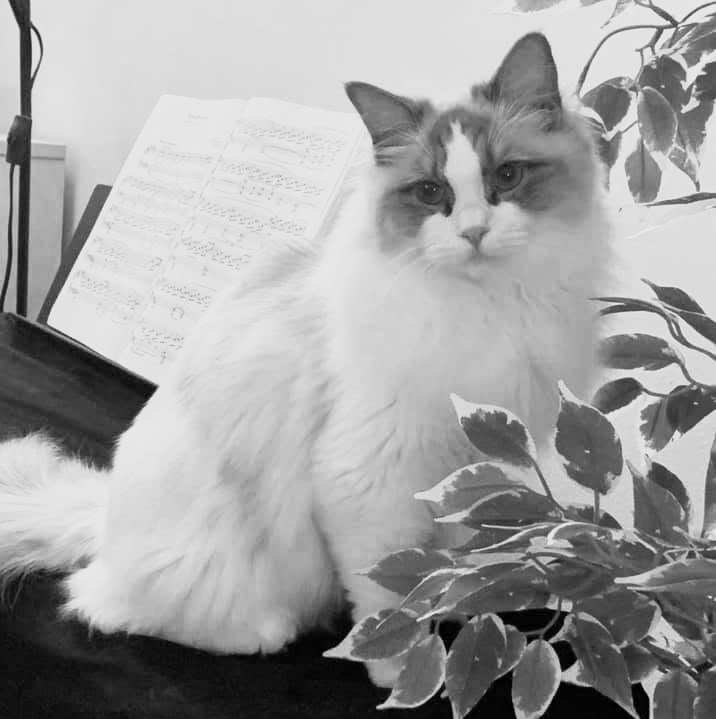

In [60]:
img = Image.open('cat2bw.png')
img

Now let's convert the image to a NumPy array.

In [61]:
ImgArr=np.array(img)
print(ImgArr)
print(f'Size = {ImgArr.shape}')

[[220 220 220 ... 229 224 220]
 [220 220 220 ... 197 180 167]
 [220 220 220 ... 118 112 106]
 ...
 [ 21  20  20 ...  63  63  63]
 [ 21  20  20 ...  64  64  64]
 [ 17  17  18 ...  64  64  64]]
Size = (719, 716)


Let's apply the SVD to `ImgArr`. The number of nonzero singular values is equal to the rank of the image matrix. In this case, the rank is $716$:

In [62]:
U, S, VT = np.linalg.svd(ImgArr)
print(f'Numerical rank = {np.linalg.matrix_rank(ImgArr)}')

Numerical rank = 716


Now we truncate $\Sigma$ to the $7 \times 7$ diagonal matrix containing the $7$ largest singular values. We also truncate $U$ and $V^T$ accordingly. We can use `np.diag()` to construct square diagonal matrix.

In [63]:
n_components =7
VT_tr = VT[:n_components, :] 
U_tr= U[:,:n_components]
Sigma_tr = np.diag(S[:n_components])
print(Sigma_tr)

[[120405.38      0.        0.        0.        0.        0.        0.  ]
 [     0.    15516.52      0.        0.        0.        0.        0.  ]
 [     0.        0.    10753.79      0.        0.        0.        0.  ]
 [     0.        0.        0.    10113.08      0.        0.        0.  ]
 [     0.        0.        0.        0.     8541.7       0.        0.  ]
 [     0.        0.        0.        0.        0.     8159.2       0.  ]
 [     0.        0.        0.        0.        0.        0.     6158.51]]


Now let's multiply the truncated matrices to obtain an approximation of the image and see what it looks like:

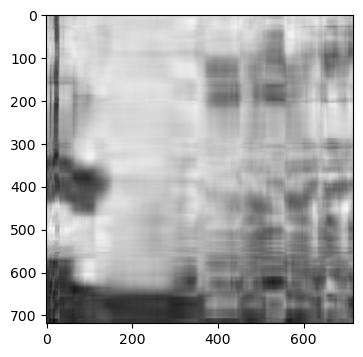

In [65]:
image_reconstructed = U_tr@Sigma_tr@VT_tr
plt.figure(figsize=(4, 4))
plt.imshow(image_reconstructed, cmap='gray')
plt.show()

How much does this compression help?
The original image is $719 \times 716$, so it contains $514,804$ pixel values.
After truncating the SVD to $7$ singular values, we need to store three pieces of information:
1. `U_tr` is $719 \times 7$ giving us $5,033$ values;
2. `Sigma_tr` is diagonal, so we only need to store its $7$ nonzero singular values;
3. `VT_tr` is $7 \times 716$ giving us $5,012$ values.

Therefore, the total number of values we need to store is $5,033+7+5,012=10,052$. This is a reduction of approximately $98\%$ in the number of stored values. 

For better quality, we can increase the number of singular values. Here are several examples of SVD-based compression of the same image. The titles show the number of singular values retained and the corresponding reduction in storage.

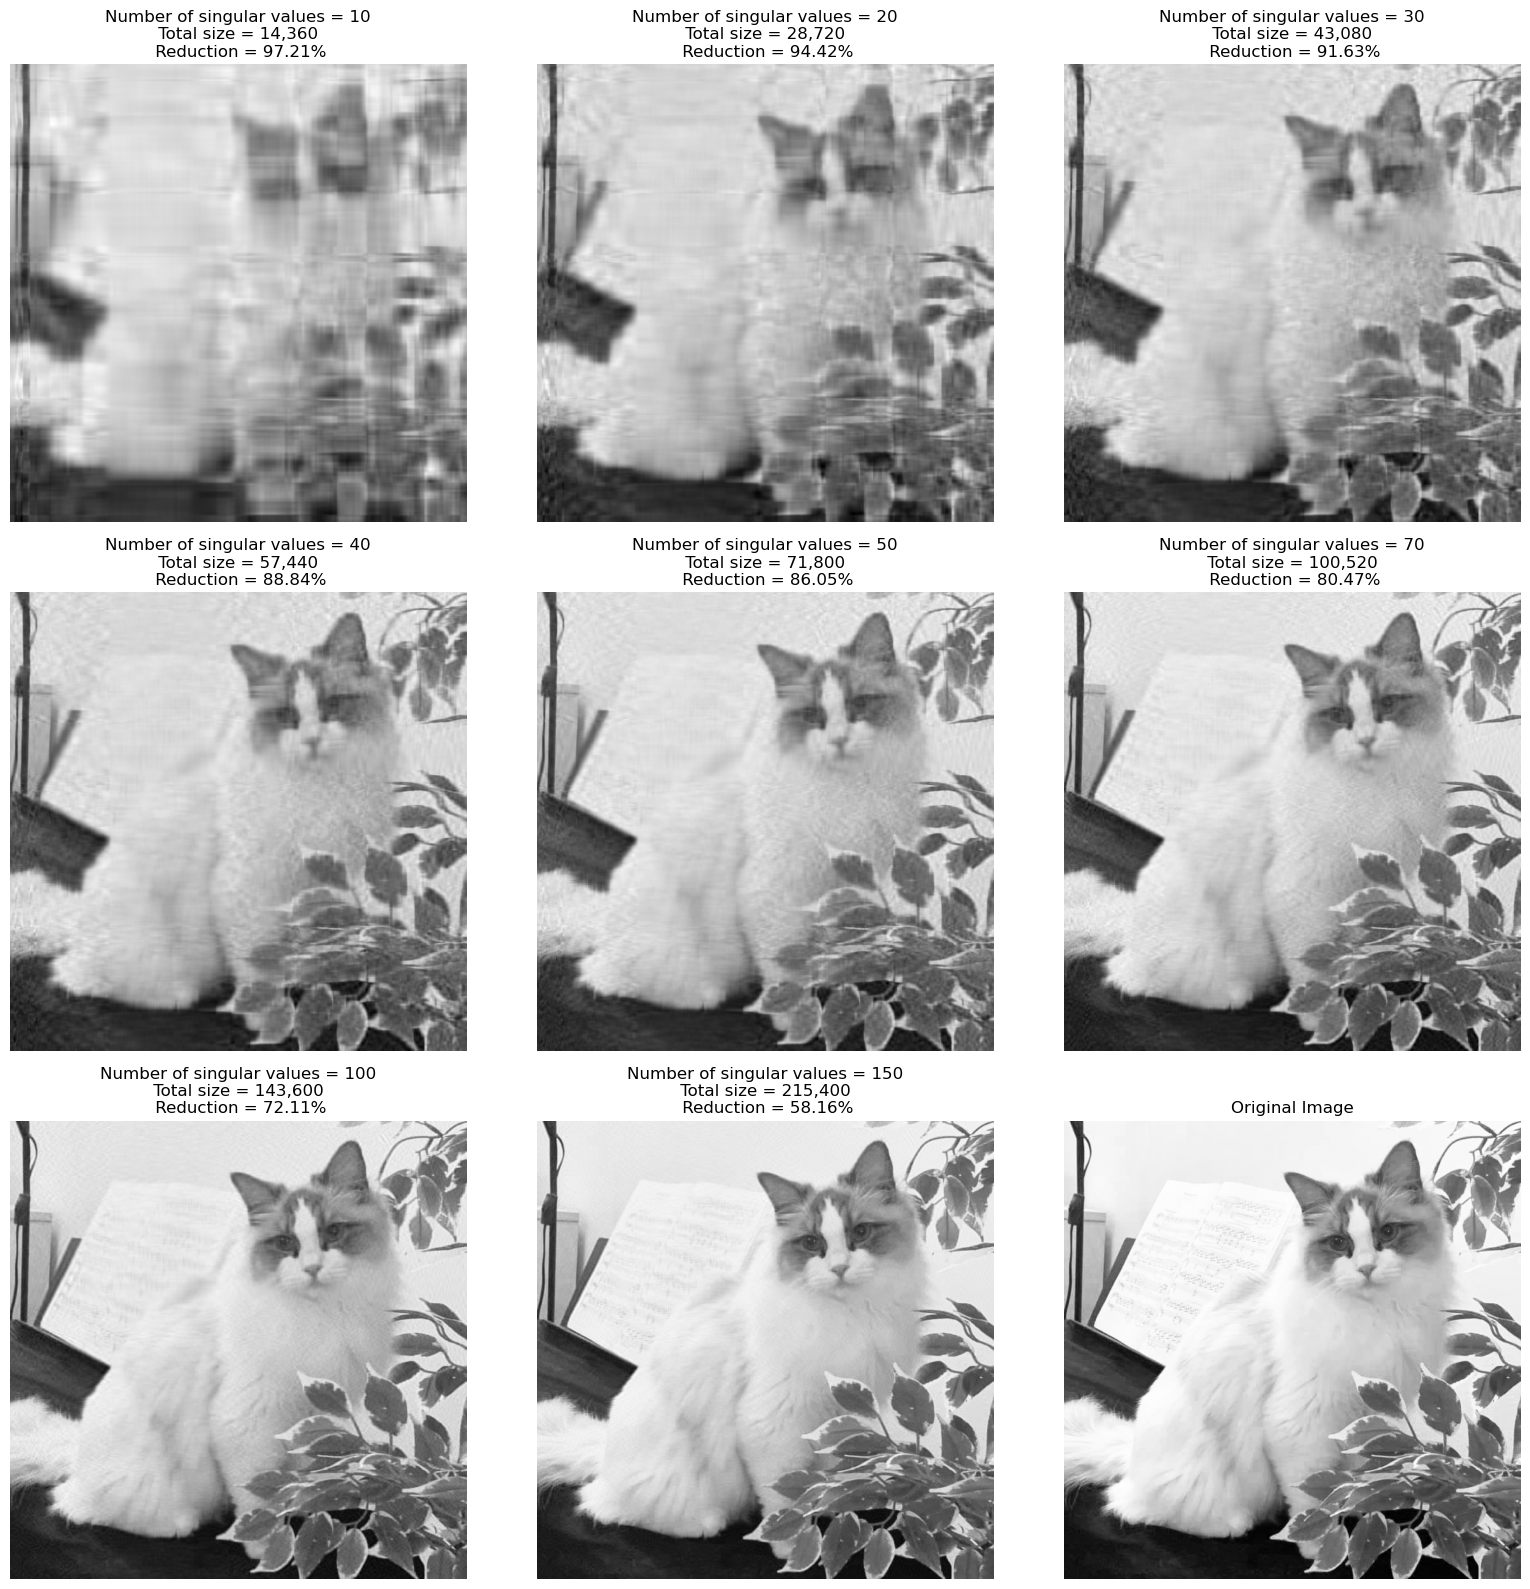

In [50]:
U, S, VT = np.linalg.svd(ImgArr)

plt.figure(figsize=(16,16))
n=0
for i in [10, 20, 30, 40, 50, 70, 100, 150]:
    plt.subplot(3, 3, n + 1)
    VT_i = VT[:i, :] 
    U_i= U[:,:i]
    Sigma_i = np.diag(S[:i])
    image_reconstructed= U_i@Sigma_i@VT_i
    size = i * (ImgArr.shape[0] + ImgArr.shape[1] + 1)
    reduction = (1 - size / ImgArr.size) * 100
    plt.imshow(image_reconstructed, cmap='gray')
    plt.title(f'Number of singular values = {i}\n Total size = {size:,} \n Reduction = {reduction:.2f}%')
    plt.axis('off')
    n += 1

plt.subplot(3, 3, n + 1)
plt.imshow(ImgArr, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.tight_layout()
plt.show()    

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> SVD is not commonly used for practical image compression because more specialized methods are faster and more effective. For example, JPEG uses the discrete cosine transform (DCT) rather than SVD. Both approaches are similar in that they represent data using a transform and discard information that contributes less to the compressed representation. However, their underlying mathematics differs.
</div> 


Another way to compute a truncated SVD is with the `TruncatedSVD` class from `scikit-learn`.

In [67]:
svd = TruncatedSVD(n_components=7)
image_reduced = svd.fit_transform(ImgArr)
print(image_reduced)

[[5661.32 -190.01  348.43 ...  379.58 -177.25    2.01]
 [5676.64 -199.12  372.58 ...  382.95 -193.67    7.26]
 [5674.97 -193.94  414.22 ...  359.77 -205.07   32.33]
 ...
 [ 778.83 -266.7   -12.52 ...  367.47  145.85 -297.13]
 [ 768.21 -265.21  -22.25 ...  365.78  146.95 -276.48]
 [ 755.53 -264.16  -31.86 ...  357.49  149.09 -251.8 ]]


The array `image_reduced` contains the coefficients of the image in the retained right singular-vector directions. We usually call these coefficients **SVD coordinates**. Mathematically, these coordinates correspond to $U_k\Sigma_k$ from the truncated SVD. We can confirm this by comparing `image_reduced` with the product of `U_tr @ SigTrunc_tr` from above.

To reconstruct the approximated image, we use `inverse_transform()`. Mathematically, this multiplies the SVD coordinates $(U_k \Sigma_k)$ by $V_k^T$, the transpose of the matrix containing the retained right singular vectors.

Thus, the SVD coordinates $U_k\Sigma_k$ describe the image in the reduced $k$-dimensional coordinate system, while multiplication by $V_k^T$ reconstructs the approximation in the original pixel space.

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #4c72b0;
    background-color: rgba(10,150,250,0.16);
    margin: 0.4em 0;
">
<strong>📌 Note:</strong> Because scikit-learn may use an approximate numerical algorithm, the computed values can differ slightly from those obtained using NumPy's full SVD.
</div> 

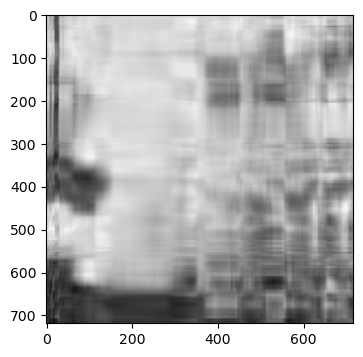

In [68]:
image_reconstructed=svd.inverse_transform(image_reduced)
plt.figure(figsize=(4, 4))
plt.imshow(image_reconstructed, cmap='gray')
plt.show()

This produces approximately the same rank-$7$ reconstruction as before.

######
<font color="#3f7fff" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Dimensionality Reduction</b>
</div></font> 

Truncated SVD has another very useful application: **dimensionality reduction**. Let's load a dataset containing images of handwritten digits. We store the pixel values of the images in the array $X$ and the corresponding digit labels in the array $y$.

In [53]:
X, y = load_digits(return_X_y=True)
X.shape, y.shape

((1797, 64), (1797,))

As you can see, $X$ is a $1797 \times 64$ array. It contains $1797$ images and each image is $8 \times 8$, for a total of $64$ pixels. Each image is stored as a one-dimensional array of length $64$. Each pixel is represented by a number between $0$ and $16$, where $0$ represents black, $16$ represents white, and values in between represent different shades of gray. 

Let's look at the first image and then see what the array $y$ tells us about this image. Because each image is stored as a list of $64$ values, we need to rearrange those values into an $8\times 8$ grid in order to display the image. We can use `reshape()` to do this.

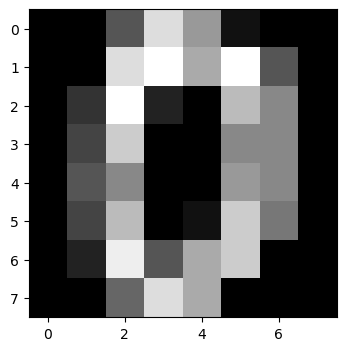

This image represents the digit 0


In [69]:
image = X[0]
image = image.reshape((8, 8))
plt.figure(figsize=(4, 4))
plt.imshow(image, cmap = 'gray')
plt.show()
print(f'This image represents the digit {y[0]}')

Here is the image as it is stored in the $8 \times 8$ array:

In [55]:
print(image)

[[ 0.  0.  5. 13.  9.  1.  0.  0.]
 [ 0.  0. 13. 15. 10. 15.  5.  0.]
 [ 0.  3. 15.  2.  0. 11.  8.  0.]
 [ 0.  4. 12.  0.  0.  8.  8.  0.]
 [ 0.  5.  8.  0.  0.  9.  8.  0.]
 [ 0.  4. 11.  0.  1. 12.  7.  0.]
 [ 0.  2. 14.  5. 10. 12.  0.  0.]
 [ 0.  0.  6. 13. 10.  0.  0.  0.]]


Each image is represented by $64$ pixel values, so we can think of each image as a point in a $64$-dimensional space. We will reduce this representation to a $5$-dimensional space and see whether the images are still recognizable. This amounts to finding a low-dimensional linear subspace through the origin and projecting the image data onto it while preserving as much of its structure as possible.

To do that, we can use `TruncatedSVD` again.

In [56]:
svd = TruncatedSVD(n_components=5)
X_reduced = svd.fit_transform(X)
X_reduced.shape

(1797, 5)

Notice that each image is represented by only $5$ values. Clearly, these values are no longer pixel intensities. Instead, each is a weighted combination of the original pixel values. For example, here is the five-dimensional representation of the first image:

In [57]:
print(X_reduced[0])

[ 45.86  -1.19 -21.1    9.49  13.04]


Now use `inverse_transform()` to reconstruct the first image from its five-dimensional representation and look at the approximation.

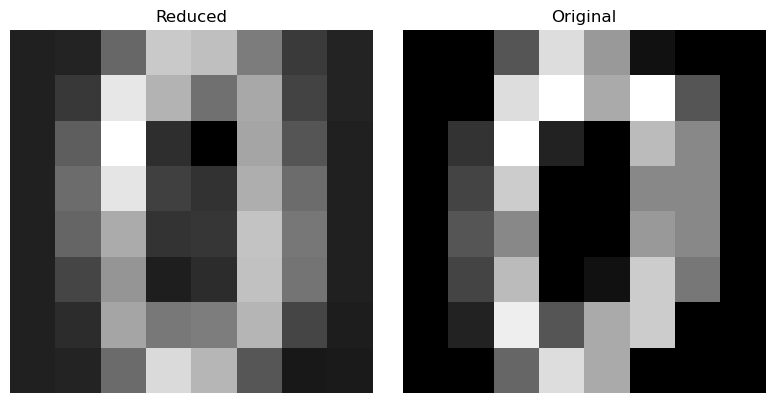

In [58]:
image_reconstructed = svd.inverse_transform(X_reduced[0].reshape(1,-1))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(image_reconstructed.reshape((8,8)), cmap = 'gray')
plt.axis('off')
plt.title('Reduced')
plt.subplot(1, 2, 2)
plt.imshow(image, cmap = 'gray')
plt.axis('off')
plt.title('Original')
plt.tight_layout()
plt.show()

---

<div style="
    font-family: Verdana, sans-serif;
    font-size: 14px;
    line-height: 1.6;
    margin: 0.8em 0;
    padding: 0.75em 1em;
    border-radius: 6px;
    border-left: 4px solid #2c3e50;
    border-left-color: #aca210;
    background-color: rgba(190,190,20,0.16);
    margin: 0.4em 0;
">
    
<strong>🛠️ <font color="magenta">Practice: </font> </strong> You should try different values for `n_components` and see how the quality of the reconstructed image changes as more singular-vector directions are retained.
</div>

---

Why does this work?

Images representing different digits tend to occupy different regions of the high-dimensional space, while images representing the same digit tend to have similar patterns and therefore tend to be relatively close to one another. For dimensionality reduction to be useful, we want to preserve these relationships as much as possible: images of different digits should remain distinguishable in the lower-dimensional representation, while images of the same digit should retain similar representations.

The components associated with large singular values capture directions that account for a large amount of the squared magnitude of the data. In image datasets, these directions often capture important visual patterns shared by many images. Retaining the components corresponding to the largest singular values therefore allows us to represent the images using far fewer numbers while preserving much of their important structure.

In many datasets, the singular values decrease relatively quickly. When this happens, a relatively small number of components can account for a large proportion of the data's total squared magnitude, making a low-dimensional approximation possible with relatively little loss of information.

######
<font color="#0fbf0f" size="5"><div style="
    font-family: Verdana;
    font-size: 1.6em;
    font-weight: 600;
    line-height: 1.3;
    padding: 0.5em 1em;
    margin: 0.5em 0 0.6em 0;
    border-top: 2px solid rgba(144,62,80,0.3);
    border-bottom: 2px solid rgba(144,62,80,0.3);
    border-radius: 8px;
">
<b>Exercises</b>
</div></font> 


**1.**
>Find the singular values of the following matrices: <br><br>
>***a.*** $\begin{bmatrix} 1 & 0 \\ 0 & 3 \end{bmatrix}; \quad \quad $
>***b.*** $\begin{bmatrix} 1 & 1 \\ 0 & 0 \end{bmatrix}; \quad \quad $
>***c.*** $\begin{bmatrix} 2 & 1 \\ 1 & 2 \end{bmatrix}$


**2.**
>Find the SVD of the following matrices: <br><br>
>***a.*** $\begin{bmatrix} 1 & -1 \\ 1 & 1 \end{bmatrix}; \quad \quad $
>***b.*** $\begin{bmatrix} 2 & 0 & 1\\ 0 & 2 & 0 \end{bmatrix}; \quad \quad $
>***c.*** $\begin{bmatrix} 3 & -3 \\ 0 & 0 \\ 1 & 1 \end{bmatrix}; \quad \quad $
>***d.*** $\begin{bmatrix} 0 & 1 \\ 1 & 0 \\ 2 & -2 \end{bmatrix}$ <br><br>

**3.**
>Find the SVD of the following matrices by first considering $A^T$  <br><br>
>***a.*** $\begin{bmatrix} 3 & 2 & 2\\ 2 & 3 & -2 \end{bmatrix}; \quad \quad $
>***b.*** $\begin{bmatrix} 1 & 1 \\ 1 & 1 \\ 1 & 1  \end{bmatrix}$ <br><br>

**4.** 
>Use Python to find the SVD of each matrix in Problem 2. For each matrix, print out $U$, $\Sigma$ and $V^T$, and verify that $A=U\Sigma V^T$.

**5.**
>For each matrix in Problem 2, use its SVD to construct a rank-1 approximation using only the largest singular value. Compare the rank-1 approximation with the original matrix.

**6.**
> Use Python for this problem.<br>
>***a.***  Load the dataset "Penguin map.csv" that we created in Chapter 1.3. Standardize the numerical columns.<br>
> ***b.*** Create a matrix $X$ using all numerical columns and compute the SVD of $X$<br>
> ***c.*** Compute $U_2\Sigma_2$, where $U_2$ contains the first two columns of $U$ and $\Sigma_2$ contains the two largest singular values. The resulting matrix has two columns. Each row represents one penguin using two SVD coordinates.<br>
> ***d.*** Create a scatter plot using the two columns of $U_2\Sigma_2$ as the horizontal and vertical coordinates. Color the points according to the species of the penguin (See Chapter 1.3 for instructions). This gives a two-dimensional approximation of the original data. Notice that the different species can still be distinguished even though the data have been reduced to two dimensions.<br>
> ***e.*** Notice that each species appears to be divided into two groups in the scatter plot. What characteristic of the penguins might explain this separation? Choose an appropriate column from the original dataset that could explain the two groups. Recreate the scatter plot, this time coloring the points according to that characteristic. Does the new coloring confirm your hypothesis?